<center><h1>Disi_Sinan_HW7</h1></center>
<br>
<br>

Name: Sinan Disi
<br>
Github Username: Sinan-Disi
<br>
USC ID: 8053361335

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.multiclass import OneVsRestClassifier
from sklearn.svm import SVC, LinearSVC
from sklearn.cluster import KMeans
from sklearn.metrics import calinski_harabasz_score, silhouette_score

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.spatial.distance import squareform

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
# Load the dataset
df = pd.read_csv("../data/Frogs_MFCCs.csv")

# Separate features and labels
X = df.iloc[:, :22]
y = df[["Family", "Genus", "Species"]]

# Split the data: 70% training, 30% testing
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42)

print("Dataset shape:", df.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

Dataset shape: (7195, 26)
Training set: (5036, 22)
Test set: (2159, 22)


### (b) Train a classifier for each label

#### (i) Research

Since each frog has three labels (Family, Genus, and Species), we use the following methods to evaluate our predictions:

**Exact Match:** Measures how often all three labels are predicted correctly. If even one label is wrong, the entire prediction is counted as incorrect.

**Hamming Loss:** Measures the proportion of labels predicted incorrectly. Lower is better, and 0 means all labels are correct.

**Hamming Score:** Measures the proportion of labels predicted correctly. It is calculated as 1 − Hamming Loss. Higher is better, and 1 means all labels are correct.

#### (ii) Train a SVM for each of the labels

In [4]:
# Gaussian SVM with 10-fold cross-validation
cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=42)
params = {"estimator__C": [0.1, 1, 10, 100, 1000],
          "estimator__gamma": [0.01, 0.1, 1, 10]}

rbf_predictions = pd.DataFrame(index=y_test.index)

for label in y_train.columns:
    svm = OneVsRestClassifier(SVC(kernel="rbf"))
    grid = GridSearchCV(svm, params, cv=cv, scoring="accuracy", n_jobs=-1)
    grid.fit(X_train, y_train[label])

    rbf_predictions[label] = grid.predict(X_test)

    best_C = grid.best_params_["estimator__C"]
    best_gamma = grid.best_params_["estimator__gamma"]
    sigma = np.sqrt(1 / (2 * best_gamma))

    print(f"{label}: C={best_C}, gamma={best_gamma}, sigma={sigma:.4f}")
    print(f"Test accuracy: {np.mean(rbf_predictions[label] == y_test[label]):.4f}")

# Multi-label evaluation
correct = rbf_predictions.values == y_test.values

exact_match = np.mean(np.all(correct, axis=1))
hamming_loss_rbf = 1 - np.mean(correct)
hamming_score_rbf = np.mean(correct)

print(f"\nExact Match: {exact_match:.4f}")
print(f"Hamming Loss: {hamming_loss_rbf:.4f}")
print(f"Hamming Score: {hamming_score_rbf:.4f}")

Family: C=1000, gamma=1, sigma=0.7071
Test accuracy: 0.9958
Genus: C=10, gamma=1, sigma=0.7071
Test accuracy: 0.9903
Species: C=10, gamma=1, sigma=0.7071
Test accuracy: 0.9907

Exact Match: 0.9875
Hamming Loss: 0.0077
Hamming Score: 0.9923


I trained a Gaussian SVM for each label using the original MFCC attributes and one-versus-all classification. I used 10-fold cross-validation to select C and gamma.

The best C was 1000 for Family and 10 for Genus and Species. Gamma was 1 (sigma = 0.7071) for all three.

Test accuracy was 99.58% for Family, 99.03% for Genus, and 99.07% for Species. Overall, Exact Match was 98.75%, Hamming Loss was 0.77%, and Hamming Score was 99.23%.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [5]:
# L1-penalized SVM with 10-fold cross-validation
l1_predictions = pd.DataFrame(index=y_test.index)
params_l1 = {"svm__C": [0.001, 0.01, 0.1, 1, 10, 100, 1000]}

for label in y_train.columns:
    model = Pipeline([("scaler", StandardScaler()),
                      ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000))])

    grid_l1 = GridSearchCV(model, params_l1, cv=cv, scoring="accuracy", n_jobs=-1)
    grid_l1.fit(X_train, y_train[label])

    l1_predictions[label] = grid_l1.predict(X_test)

    best_C = grid_l1.best_params_["svm__C"]
    accuracy = np.mean(l1_predictions[label] == y_test[label])
    print(f"{label}: C={best_C}, Test accuracy={accuracy:.4f}")

# Multi-label evaluation
l1_correct = l1_predictions.values == y_test.values

exact_match_l1 = np.mean(np.all(l1_correct, axis=1))
hamming_loss_l1 = 1 - np.mean(l1_correct)
hamming_score_l1 = np.mean(l1_correct)

print(f"\nExact Match: {exact_match_l1:.4f}")
print(f"Hamming Loss: {hamming_loss_l1:.4f}")
print(f"Hamming Score: {hamming_score_l1:.4f}")

Family: C=10, Test accuracy=0.9282
Genus: C=1000, Test accuracy=0.9416
Species: C=10, Test accuracy=0.9592

Exact Match: 0.9125
Hamming Loss: 0.0570
Hamming Score: 0.9430


I trained an L1-penalized linear SVM using standardized attributes. I used 10-fold cross-validation to find the best C for each label.

The best C was 10 for Family, 1000 for Genus, and 10 for Species.

Test accuracy was 92.82% for Family, 94.16% for Genus, and 95.92% for Species. Exact Match was 91.25%, Hamming Loss was 5.70%, and Hamming Score was 94.30%.

The L1-SVM had lower test accuracy than the Gaussian SVM in part (ii).

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [6]:
# L1-SVM with SMOTE
smote_predictions = pd.DataFrame(index=y_test.index)

for label in y_train.columns:
    model = ImbPipeline([("scaler", StandardScaler()),
                         ("smote", SMOTE(random_state=42)),
                         ("svm", LinearSVC(penalty="l1", dual=False, max_iter=20000))])

    grid_smote = GridSearchCV(model, params_l1, cv=cv, scoring="accuracy", n_jobs=2)
    grid_smote.fit(X_train, y_train[label])

    smote_predictions[label] = grid_smote.predict(X_test)

    best_C = grid_smote.best_params_["svm__C"]
    accuracy = np.mean(smote_predictions[label] == y_test[label])
    print(f"{label}: C={best_C}, Test accuracy={accuracy:.4f}")

# Multi-label evaluation
smote_correct = smote_predictions.values == y_test.values

exact_match_smote = np.mean(np.all(smote_correct, axis=1))
hamming_loss_smote = 1 - np.mean(smote_correct)
hamming_score_smote = np.mean(smote_correct)

print(f"\nExact Match: {exact_match_smote:.4f}")
print(f"Hamming Loss: {hamming_loss_smote:.4f}")
print(f"Hamming Score: {hamming_score_smote:.4f}")

Family: C=10, Test accuracy=0.9092
Genus: C=1, Test accuracy=0.9023
Species: C=10, Test accuracy=0.9579

Exact Match: 0.8536
Hamming Loss: 0.0769
Hamming Score: 0.9231


I used SMOTE with the L1-SVM to handle class imbalance. I also used standardized attributes and 10-fold cross-validation.

The best C was 10 for Family, 1 for Genus, and 10 for Species.

Test accuracy was 90.92% for Family, 90.23% for Genus, and 95.79% for Species. Exact Match was 85.36%, Hamming Loss was 7.69%, and Hamming Score was 92.31%.

SMOTE did not improve the results compared to the L1-SVM without SMOTE. The Gaussian SVM in part (ii) still had the best results.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [8]:
# Use the whole dataset
X_full = df.iloc[:, :22].to_numpy()
y_full = df[["Family", "Genus", "Species"]].reset_index(drop=True)

best_ks = []
cluster_runs = []

# 50 Monte Carlo runs
for run in range(50):
    best_score = -1

    for k in range(2, 51):
        clusters = KMeans(n_clusters=k, random_state=run, n_init=1).fit_predict(X_full)
        score = silhouette_score(X_full, clusters, sample_size=1000, random_state=run)

        if score > best_score:
            best_score = score
            best_k = k
            best_clusters = clusters

    best_ks.append(best_k)
    cluster_runs.append(best_clusters)

print("Selected K values:")
print(pd.Series(best_ks).value_counts().sort_index())

Selected K values:
2     6
3    14
4    22
5     1
6     7
Name: count, dtype: int64


I used K-Means clustering on the whole dataset without splitting it into training and testing sets.

I repeated the clustering 50 times. For each run, I tested K values from 2 to 50 and selected the K with the highest silhouette score. I started at K = 2 because the silhouette score cannot be calculated for K = 1.

I used a sample of 1,000 observations to calculate the silhouette score and reduce running time. K-Means was still fitted on the whole dataset.

### (b) Determine which family is the majority

In [9]:
majority_predictions = []

for run, clusters in enumerate(cluster_runs):
    predictions = y_full.copy()
    rows = []

    for cluster in np.unique(clusters):
        mask = clusters == cluster
        majority = y_full.loc[mask].mode().iloc[0]

        predictions.loc[mask] = majority.values
        rows.append([cluster, mask.sum(), *majority.values])

    majority_predictions.append(predictions)

    if run == 0:
        first_majorities = pd.DataFrame(rows, columns=["Cluster", "Size", "Family", "Genus", "Species"])

print("Majority labels - First Run:")
display(first_majorities)

Majority labels - First Run:


,Cluster,Size,Family,Genus,Species
0,0,3584,Leptodactylidae,Adenomera,AdenomeraHylaedactylus
1,1,2216,Hylidae,Hypsiboas,HypsiboasCordobae
2,2,663,Hylidae,Hypsiboas,HypsiboasCinerascens
3,3,732,Leptodactylidae,Adenomera,AdenomeraAndre


For each cluster, I used the true labels to find the most common Family, Genus, and Species.

In the first run, K-Means selected 4 clusters. The largest cluster had 3,584 observations, while the smallest had 663.

I repeated this for all 50 runs and assigned the majority label triplet to the observations in each cluster.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [10]:
results = []

for predictions in majority_predictions:
    incorrect = predictions.to_numpy() != y_full.to_numpy()

    hamming_distance = np.mean(np.sum(incorrect, axis=1))
    hamming_loss = np.mean(incorrect)
    hamming_score = 1 - hamming_loss

    results.append([hamming_distance, hamming_score, hamming_loss])

results_df = pd.DataFrame(results, columns=["Hamming Distance", "Hamming Score", "Hamming Loss"])

print("50 Monte Carlo Runs:")
print(results_df.agg(["mean", "std"]).round(4))

50 Monte Carlo Runs:
      Hamming Distance  Hamming Score  Hamming Loss
mean            0.7223         0.7592        0.2408
std             0.1289         0.0430        0.0430


I calculated the Hamming distance, Hamming score, and Hamming loss for all 50 runs.

The average Hamming distance was 0.7223, with a standard deviation of 0.1289. This means around 0.72 out of the 3 labels were incorrect per observation.

The average Hamming score was 75.92%, and the average Hamming loss was 24.08%. Both had a standard deviation of 4.30%.

## 3. ISLR 12.6.2

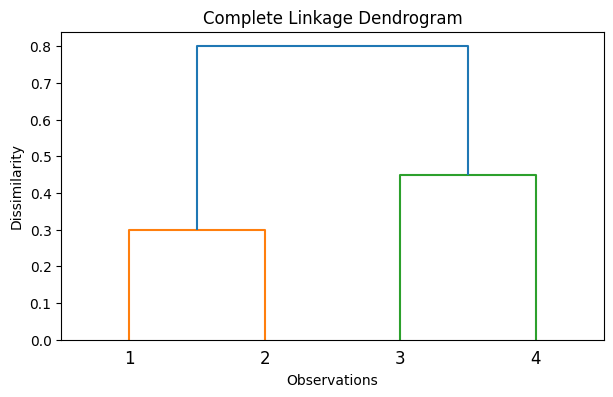

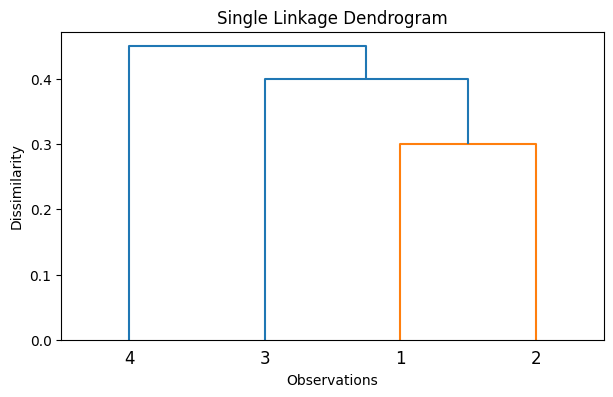

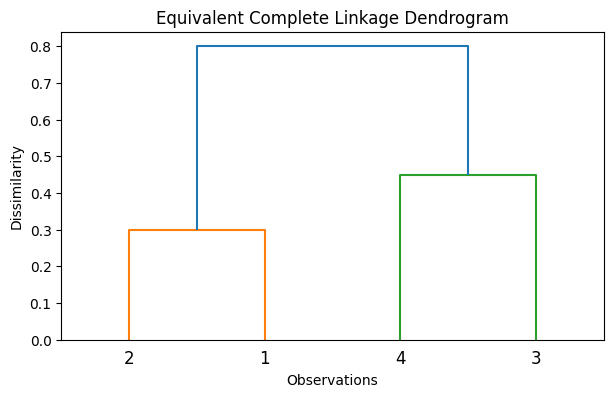

In [6]:
# a) Dissimilarity matrix
dist_matrix = np.array([
    [0, 0.3, 0.4, 0.7],
    [0.3, 0, 0.5, 0.8],
    [0.4, 0.5, 0, 0.45],
    [0.7, 0.8, 0.45, 0]])

# Complete linkage 
complete_linkage = linkage(squareform(dist_matrix), method="complete")

# Plot dendrogram
plt.figure(figsize=(7, 4))
dendrogram(complete_linkage, labels=["1", "2", "3", "4"])
plt.title("Complete Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Dissimilarity")
plt.show()

# b)Single linkage 
single_linkage = linkage(squareform(dist_matrix), method="single")

# Plot dendrogram
plt.figure(figsize=(7, 4))
dendrogram(single_linkage, labels=["1", "2", "3", "4"])
plt.title("Single Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Dissimilarity")
plt.show()

# (e) Equivalent dendrogram
equivalent_linkage = complete_linkage.copy()

# Swap the positions of observations within each pair
equivalent_linkage[0, :2] = complete_linkage[0, :2][::-1]
equivalent_linkage[1, :2] = complete_linkage[1, :2][::-1]

plt.figure(figsize=(7, 4))
dendrogram(equivalent_linkage, labels=["1", "2", "3", "4"])
plt.title("Equivalent Complete Linkage Dendrogram")
plt.xlabel("Observations")
plt.ylabel("Dissimilarity")
plt.show()

### ISLR 12.6.2 — Explanations

**(a) Complete Linkage**

Complete linkage uses the largest distance between two clusters. Observations 1 and 2 merge at 0.30, then 3 and 4 merge at 0.45. Finally, both clusters merge at 0.80.

**(b) Single Linkage**

Single linkage uses the smallest distance between two clusters. Observations 1 and 2 merge at 0.30, then observation 3 joins at 0.40, followed by observation 4 at 0.45.

**(c) Complete Linkage — Two Clusters**

If we cut the dendrogram to get two clusters, we have:

- Cluster 1: {1, 2}
- Cluster 2: {3, 4}

**(d) Single Linkage — Two Clusters**

If we cut the dendrogram to get two clusters, we have:

- Cluster 1: {1, 2, 3}
- Cluster 2: {4}

**(e) Equivalent Dendrogram**

We can switch the positions of observations 1 and 2, and 3 and 4. This changes how the dendrogram looks, but the clusters and their merging heights stay the same. Therefore, both dendrograms represent the same clustering.

### AI Assistance Disclosure and Prompts Used

AI Assistance Disclosure and Prompts Used

I used AI mainly to help understand the assignment, clarify programming and statistical concepts, and get Python coding examples for SVM classification, cross-validation, SMOTE, and K-Means clustering. I also used it to better understand the concepts in Section 3 (ISLR 12.6.2). I ran the final code and reviewed the answers before submission.

Prompts:

1) Can you show me a simple Python example of training an SVM with a Gaussian kernel and using cross-validation to select the best parameters?

2) Can you explain L1-penalized SVMs and show me how to standardize features and apply SMOTE to handle class imbalance?

3) Can you explain the concepts behind ISLR 12.6.2, including hierarchical clustering, dendrograms, and linkage methods, with a simple example?